# Huấn luyện YOLO11s đếm người trên ShanghaiTech Part B bằng Google Colab

Thí nghiệm dùng cùng cách chia **360 train / 40 validation / 316 test** với CSRNet. YOLO11s học phát hiện đầu người từ hộp xấp xỉ quanh mỗi điểm nhãn. Cả hai mô hình được đánh giá bằng **MAE và RMSE** trên số người gốc trong file MAT.

## Chạy trên Colab

1. Tải notebook lên Colab. Chọn **Runtime → Change runtime type → GPU**, rồi chọn **Run all**.
2. Notebook tự tải ShanghaiTech phiên bản 1. Nếu đã có dữ liệu, đặt **DATA_ROOT** thành đường dẫn thư mục giải nén hoặc file ZIP gốc trong Colab. [Bộ dữ liệu ShanghaiTech](https://www.kaggle.com/datasets/tthien/shanghaitech)
3. Sau khi chạy, nhận file **yolo_partb_outputs.zip** từ ô cuối hoặc mở bảng **Files** để tải. Đặt **SAVE_TO_DRIVE = True** ở ô cấu hình nếu muốn lưu ZIP kết quả vào Google Drive sau khi chạy xong.

Kết quả CSRNet đã lưu có sẵn để đối chiếu. Có thể tải **csrnet_partB.pth** lên Colab để chạy lại CSRNet trên từng ảnh test.

## 1. Cài đặt và cấu hình

In [ ]:
%pip -q install "ultralytics==8.3.228"

In [ ]:
import hashlib
import json
import random
import shutil
import tempfile
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import display
from scipy.io import loadmat
from scipy.spatial import cKDTree
from ultralytics import YOLO

DATA_ROOT = None  # Thư mục dữ liệu hoặc ZIP gốc, ví dụ "/content/shanghaitech.zip"
YOLO_WEIGHTS = None  # Có thể dùng trọng số có sẵn, ví dụ "/content/yolo11s.pt"
CSRNET_CHECKPOINT = None  # Tự dùng /content/csrnet_partB.pth nếu file có mặt
SAVE_TO_DRIVE = False  # True để lưu ZIP cuối vào MyDrive/ShanghaiTech_YOLO

CFG = dict(
    model="yolo11s.pt",
    epochs=150,
    batch=4,
    imgsz=1024,
    workers=2,
    seed=42,
    val_ratio=0.1,
    eval_every=5,
    iou=0.65,
    max_det=1200,
    conf_grid=(0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60),
    box_neighbor_factor=0.65,
    box_min_px=8.0,
    box_max_px=40.0,
)

if not torch.cuda.is_available():
    raise RuntimeError("Hãy bật GPU trong Runtime → Change runtime type rồi chạy lại.")
DEVICE = 0
GPU = torch.cuda.get_device_name(DEVICE)
COLAB_ROOT = Path("/content")
DATA_CACHE = COLAB_ROOT / "shanghaitech_v1"
EXPORT = COLAB_ROOT
if SAVE_TO_DRIVE:
    from google.colab import drive

    drive.mount(str(COLAB_ROOT / "drive"))
    EXPORT = COLAB_ROOT / "drive" / "MyDrive" / "ShanghaiTech_YOLO"
WORK = Path(tempfile.mkdtemp(prefix="yolo_partb_", dir=COLAB_ROOT))
OUT = WORK / "outputs"
OUT.mkdir()
EXPORT.mkdir(parents=True, exist_ok=True)
print(f"GPU {GPU} | PyTorch {torch.__version__} | Ultralytics {ultralytics.__version__}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU Tesla T4 | PyTorch 2.14.1+cu130 | Ultralytics 8.3.228


## 2. Đọc dữ liệu và chia tập như CSRNet

Phiên bản CSRNet đã chạy dùng bản ShanghaiTech phiên bản 1. Cả hai notebook sắp xếp tên file JPG theo thứ tự từ điển, xáo trộn chỉ số bằng **random.Random(42)** rồi lấy 40 ảnh đầu làm validation. Tập test giữ nguyên theo bộ dữ liệu gốc.

In [ ]:
def find_part_b(root):
    root = Path(root)
    if not root.is_dir():
        return []
    matches = sorted({
        train_dir.parent
        for train_dir in root.rglob("train_data")
        if train_dir.parent.name.lower().startswith("part_b")
        and (train_dir / "images").is_dir()
        and (train_dir.parent / "test_data" / "images").is_dir()
    })
    original = [path for path in matches if "shanghaitech_h5_empty" not in path.parts]
    return original or matches


def extract_part_b_archive(archive, destination):
    from zipfile import ZipFile

    with tempfile.TemporaryDirectory(prefix="shanghaitech_extract_", dir=destination.parent) as temporary:
        extracted = Path(temporary) / "data"
        with ZipFile(archive) as bundle:
            members = [
                info for info in bundle.infolist()
                if info.filename.startswith("ShanghaiTech/part_B/")
                and Path(info.filename).suffix.lower() in (".jpg", ".mat")
            ]
            if not members:
                raise ValueError("File ZIP cần có ảnh và nhãn dưới ShanghaiTech/part_B/.")
            for info in members:
                relative = Path(info.filename)
                if not (extracted / relative).resolve().is_relative_to(extracted.resolve()):
                    raise ValueError(f"Đường dẫn trong ZIP không hợp lệ: {info.filename}")
            bundle.extractall(extracted, members=members)
        extracted.rename(destination)


def download_part_b_archive(destination):
    import requests
    from requests.adapters import HTTPAdapter
    from tqdm.auto import tqdm
    from urllib3.util.retry import Retry

    url = "https://api.kaggle.com/v1/datasets/download/tthien/shanghaitech?datasetVersionNumber=1"
    retry = Retry(total=2, backoff_factor=2, status_forcelist=(429, 500, 502, 503, 504))
    with tempfile.TemporaryDirectory(prefix="shanghaitech_download_", dir=WORK) as temporary:
        archive = Path(temporary) / "dataset.zip"
        with requests.Session() as session:
            session.mount("https://", HTTPAdapter(max_retries=retry))
            with session.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                total = int(response.headers.get("Content-Length", 0)) or None
                with archive.open("wb") as stream, tqdm(
                    desc="ShanghaiTech v1", total=total, unit="B", unit_scale=True
                ) as progress:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        stream.write(chunk)
                        progress.update(len(chunk))
        extract_part_b_archive(archive, destination)


if DATA_ROOT:
    root = Path(DATA_ROOT).expanduser()
    if not root.exists():
        raise FileNotFoundError(f"DATA_ROOT không tồn tại: {root}")
    if root.is_file():
        archive = root
        root = Path(tempfile.mkdtemp(prefix="shanghaitech_local_", dir=WORK)) / "data"
        extract_part_b_archive(archive, root)
else:
    root = DATA_CACHE
    if not root.exists():
        try:
            download_part_b_archive(root)
        except Exception as error:
            raise RuntimeError(
                "Chưa tải được ShanghaiTech. Bạn có thể tải ZIP gốc từ trang dataset, "
                "tải file lên Colab và đặt DATA_ROOT thành đường dẫn file ZIP rồi chạy lại. "
                f"Chi tiết: {type(error).__name__}: {error}"
            ) from error

candidates = find_part_b(root)
if len(candidates) != 1:
    raise RuntimeError(f"Cần đúng một thư mục Part B. Kiểm tra DATA_ROOT. Tìm được {candidates}")
PART_B = candidates[0]
print(PART_B)


def list_items(split):
    folder = PART_B / f"{split}_data"
    items = []
    for image in sorted((folder / "images").glob("*.jpg")):
        gt = folder / "ground-truth" / f"GT_{image.stem}.mat"
        if not gt.is_file():
            raise FileNotFoundError(gt)
        items.append({"name": image.stem, "image": image, "gt": gt})
    return items


def read_points(mat_path):
    points = loadmat(mat_path)["image_info"][0, 0][0, 0][0]
    points = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    if not np.isfinite(points).all():
        raise ValueError(f"Tọa độ không hữu hạn trong {mat_path}")
    return points


train_all = list_items("train")
test_items = list_items("test")
if (len(train_all), len(test_items)) != (400, 316):
    raise ValueError(f"Part B cần 400 ảnh train gốc và 316 ảnh test. Đang có {len(train_all)}, {len(test_items)}.")

indices = list(range(len(train_all)))
random.Random(CFG["seed"]).shuffle(indices)
n_val = int(len(indices) * CFG["val_ratio"])
val_items = [train_all[i] for i in indices[:n_val]]
train_items = [train_all[i] for i in indices[n_val:]]
for item in train_all:
    item["points"] = read_points(item["gt"])
    item["count"] = len(item["points"])
if sum(item["count"] for item in train_all) != 49151:
    raise ValueError("Tổng số điểm trên 400 ảnh train khác với bản dùng để huấn luyện CSRNet.")

print(f"{len(train_items)} train / {len(val_items)} validation / {len(test_items)} test")

ShanghaiTech v1:   0%|          | 0.00/349M [00:00<?, ?B/s]

/content/shanghaitech_v1/ShanghaiTech/part_B
360 train / 40 validation / 316 test


## 3. Tạo nhãn đầu người cho YOLO

Dùng hộp vuông tại mỗi điểm. Cạnh hộp bằng **0,65 × khoảng cách tới điểm đầu gần nhất**, giới hạn từ **8 đến 40 pixel**, sau đó cắt theo biên ảnh. Hộp được lưu với một lớp **head** theo định dạng YOLO, dùng tọa độ chuẩn hóa. Chỉ tạo hộp cho train và validation. Trình đọc nhãn Ultralytics gộp các hộp có tọa độ trùng nhau. Khi tính MAE và RMSE trên validation và test, notebook giữ đủ số điểm trong file MAT. Các chỉ số mAP xuất hiện trong log YOLO đo độ khớp với hộp xấp xỉ. [Định dạng dữ liệu YOLO](https://docs.ultralytics.com/datasets/detect/)

In [ ]:
def read_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Không đọc được ảnh {path}")
    return image


def head_boxes(points, width, height):
    if len(points) == 0:
        return np.empty((0, 4), dtype=np.float64)
    centers = np.clip(points.astype(np.float64), [0, 0], [width - 1, height - 1])
    if len(centers) == 1:
        sides = np.full(1, CFG["box_max_px"])
    else:
        distance = cKDTree(centers).query(centers, k=2)[0][:, 1]
        sides = np.clip(CFG["box_neighbor_factor"] * distance, CFG["box_min_px"], CFG["box_max_px"])
    radius = sides[:, None] / 2
    lower = np.maximum(centers - radius, 0)
    upper = np.minimum(centers + radius, [width, height])
    return np.column_stack((lower, upper))


def normalized_labels(boxes, width, height):
    lower, upper = boxes[:, :2], boxes[:, 2:]
    xywh = np.column_stack(((lower + upper) / 2, upper - lower))
    return xywh / [width, height, width, height]


def write_yolo_split(root, split, items):
    image_dir = root / "images" / split
    label_dir = root / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    duplicated = 0
    for item in items:
        height, width = read_image(item["image"]).shape[:2]
        boxes = head_boxes(item["points"], width, height)
        labels = normalized_labels(boxes, width, height)
        duplicated += len(labels) - len(np.unique(labels, axis=0))
        target = image_dir / item["image"].name
        shutil.copyfile(item["image"], target)
        lines = ["0 " + " ".join(f"{value:.9f}" for value in box) for box in labels]
        (label_dir / f"{item['name']}.txt").write_text(
            "\n".join(lines) + ("\n" if lines else ""), encoding="utf-8"
        )
    print(f"{split}: {len(items)} ảnh, {sum(it['count'] for it in items)} điểm, {duplicated} hộp trùng tọa độ")


YOLO_DATA = WORK / "dataset"
DATA_YAML = YOLO_DATA / "data.yaml"
write_yolo_split(YOLO_DATA, "train", train_items)
write_yolo_split(YOLO_DATA, "val", val_items)
# JSON cũng là YAML hợp lệ. Dùng đường dẫn tuyệt đối để Ultralytics tìm đúng thư mục.
DATA_YAML.write_text(json.dumps({
    "path": str(YOLO_DATA),
    "train": "images/train",
    "val": "images/val",
    "names": {0: "head"},
}, indent=2), encoding="utf-8")

train: 360 ảnh, 43502 điểm, 33 hộp trùng tọa độ
val: 40 ảnh, 5649 điểm, 5 hộp trùng tọa độ


136

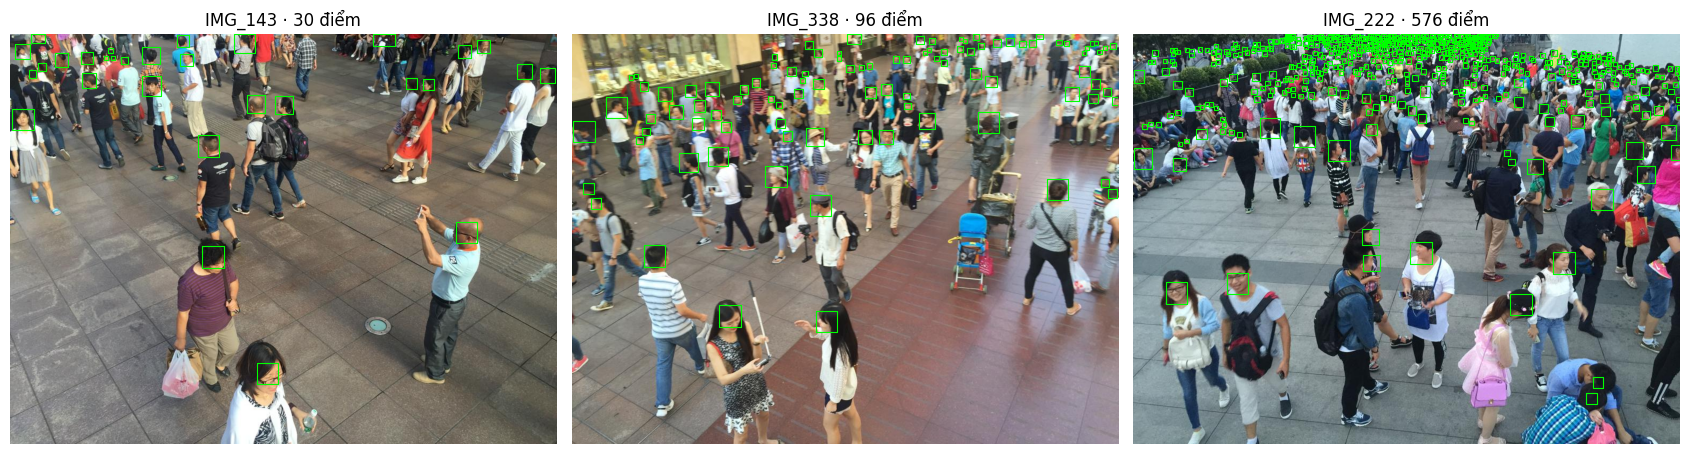

In [ ]:
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle


def draw_boxes(ax, boxes, color):
    patches = [Rectangle((x0, y0), x1 - x0, y1 - y0) for x0, y0, x1, y1 in boxes]
    ax.add_collection(PatchCollection(patches, facecolor="none", edgecolor=color, linewidths=0.8))


ordered_train = sorted(train_items, key=lambda item: item["count"])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, index in zip(axes, (len(ordered_train) // 10, len(ordered_train) // 2, -1)):
    item = ordered_train[index]
    image = cv2.cvtColor(read_image(item["image"]), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    ax.imshow(image)
    draw_boxes(ax, head_boxes(item["points"], width, height), "lime")
    ax.set_title(f"{item['name']} · {item['count']} điểm")
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "pseudo_labels_train.png", dpi=150)
plt.show()

## 4. Huấn luyện và chọn checkpoint theo MAE validation

Fine-tune YOLO11s từ trọng số COCO, với cạnh dài đầu vào 1024 px. Đánh giá đếm ở epoch đầu, mỗi 5 epoch và epoch cuối. Tại mỗi lần đánh giá, thử các ngưỡng confidence trong cấu hình trên cùng dự đoán sau NMS. Dùng ngưỡng NMS IoU cố định 0,65 và tối đa 1.200 phát hiện/ảnh vì ảnh đông nhất của bộ dữ liệu có hơn 300 người.

Chọn cặp **epoch và confidence** có MAE validation thấp nhất. Khi MAE bằng nhau, ưu tiên RMSE nhỏ hơn, rồi tới epoch sớm hơn. Trọng số được chọn lưu thành **yolo11s_partB_best_count.pt**. Ngưỡng confidence đi kèm nằm trong **results.json**. [YOLO11](https://docs.ultralytics.com/models/yolo11/) · [Callback sau khi lưu checkpoint](https://docs.ultralytics.com/usage/callbacks/)

In [ ]:
def count_metrics(predicted, ground_truth):
    pred = np.asarray(predicted, dtype=np.float64)
    gt = np.asarray(ground_truth, dtype=np.float64)
    error = pred - gt
    return {
        "mae": float(np.mean(np.abs(error))),
        "rmse": float(np.sqrt(np.mean(error ** 2))),
        "mean_signed_error": float(np.mean(error)),
    }


def predict_heads(detector, image_dir, items, keep_boxes=False):
    expected = {item["name"] for item in items}
    by_name = {}
    stream = detector.predict(
        source=str(image_dir), stream=True, device=DEVICE, imgsz=CFG["imgsz"],
        batch=1, rect=True, half=(DEVICE != "cpu"), conf=min(CFG["conf_grid"]),
        iou=CFG["iou"], max_det=CFG["max_det"], verbose=False, save=False,
    )
    for result in stream:
        name = Path(result.path).stem
        if name not in expected or name in by_name:
            raise ValueError(f"Tên ảnh ngoài danh sách hoặc bị lặp: {result.path}")
        record = {"scores": result.boxes.conf.float().cpu().numpy()}
        if keep_boxes:
            record["boxes"] = result.boxes.xyxy.float().cpu().numpy()
            record["speed_ms"] = sum(result.speed.values())
        by_name[name] = record

    missing = expected - by_name.keys()
    if missing:
        raise ValueError(f"YOLO thiếu dự đoán cho {len(missing)} ảnh, ví dụ {sorted(missing)[:5]}")
    return [by_name[item["name"]] for item in items]


def counts_at_threshold(records, confidence):
    return np.asarray([np.count_nonzero(row["scores"] > confidence) for row in records])

In [ ]:
initial_weights = Path(YOLO_WEIGHTS).expanduser().resolve() if YOLO_WEIGHTS else WORK / CFG["model"]
if YOLO_WEIGHTS and not initial_weights.is_file():
    raise FileNotFoundError(initial_weights)

VAL_HISTORY = OUT / "validation_count_sweep.csv"
BEST_YOLO = OUT / "yolo11s_partB_best_count.pt"
VAL_SELECTION = OUT / "validation_selection.json"
val_history = []
best_count = None


def select_by_val_count(trainer):
    global best_count

    epoch = trainer.epoch + 1
    if epoch != 1 and epoch % CFG["eval_every"] and epoch != trainer.epochs:
        return

    candidate = YOLO(str(trainer.last))
    predictions = predict_heads(candidate, YOLO_DATA / "images" / "val", val_items)
    gt = [item["count"] for item in val_items]
    rows = []
    for confidence in CFG["conf_grid"]:
        scores = count_metrics(counts_at_threshold(predictions, confidence), gt)
        rows.append({"epoch": epoch, "confidence": confidence, **scores})
    val_history.extend(rows)
    pd.DataFrame(val_history).to_csv(VAL_HISTORY, index=False)

    def ranking(row):
        return row["mae"], row["rmse"], row["epoch"], row["confidence"]

    epoch_best = min(rows, key=ranking)
    if best_count is None or ranking(epoch_best) < ranking(best_count):
        shutil.copy2(trainer.last, BEST_YOLO)
        best_count = epoch_best
        VAL_SELECTION.write_text(
            json.dumps(best_count, indent=2, ensure_ascii=False), encoding="utf-8"
        )

    print(f"Validation đếm epoch {epoch:3d} | conf {epoch_best['confidence']:.2f} | "
          f"MAE {epoch_best['mae']:.3f} | RMSE {epoch_best['rmse']:.3f} | "
          f"MAE tốt nhất {best_count['mae']:.3f}")


yolo = YOLO(str(initial_weights))
yolo.add_callback("on_model_save", select_by_val_count)
training_start = time.perf_counter()
yolo.train(
    data=str(DATA_YAML), epochs=CFG["epochs"], imgsz=CFG["imgsz"], batch=CFG["batch"],
    device=DEVICE, workers=CFG["workers"], seed=CFG["seed"], deterministic=True,
    patience=0, amp=(DEVICE != "cpu"), max_det=CFG["max_det"], iou=CFG["iou"],
    project=str(WORK / "runs"), name="yolo11s_partb", plots=True,
)
training_minutes = (time.perf_counter() - training_start) / 60

if best_count is None or not BEST_YOLO.is_file():
    raise RuntimeError("Không có checkpoint được đánh giá theo MAE validation.")

shutil.copy2(yolo.trainer.save_dir / "results.csv", OUT / "training_log_yolo.csv")
print(f"Chọn epoch {best_count['epoch']} với confidence {best_count['confidence']:.2f} "
      f"sau {training_minutes:.1f} phút huấn luyện và validation.")

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.228 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_partb_y_ojc21a/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.65, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1200, mixup=0.0, mode=train, model=/content/yolo_partb_y_ojc21a/yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=

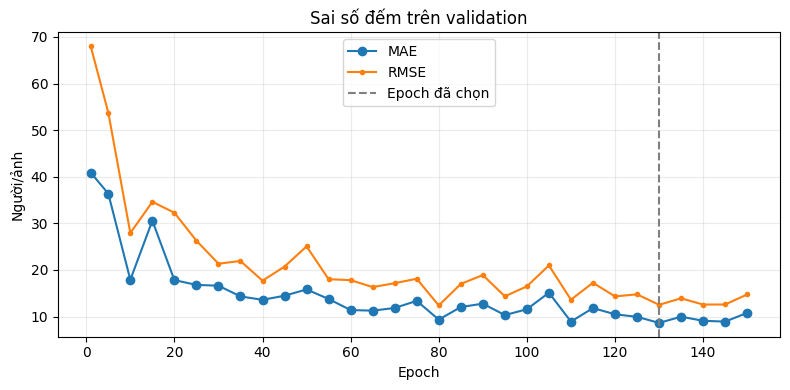

In [ ]:
val_best_by_epoch = (
    pd.read_csv(VAL_HISTORY)
    .sort_values(["mae", "rmse", "confidence"])
    .drop_duplicates("epoch")
    .sort_values("epoch")
)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(val_best_by_epoch["epoch"], val_best_by_epoch["mae"], "o-", label="MAE")
ax.plot(val_best_by_epoch["epoch"], val_best_by_epoch["rmse"], ".-", label="RMSE")
ax.axvline(best_count["epoch"], linestyle="--", color="0.5", label="Epoch đã chọn")
ax.set(xlabel="Epoch", ylabel="Người/ảnh", title="Sai số đếm trên validation")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "validation_curves.png", dpi=160)
plt.show()

## 5. Đánh giá YOLO trên 316 ảnh test

Giữ nguyên checkpoint và confidence đã chọn từ validation. Tính MAE là trung bình sai số tuyệt đối. RMSE là căn bậc hai của trung bình bình phương sai số. Cả hai chỉ số tính theo đơn vị **người/ảnh** và giá trị nhỏ hơn thể hiện sai số thấp hơn. Sai số có dấu được tính bằng dự đoán trừ nhãn gốc.

In [ ]:
for item in test_items:
    item["points"] = read_points(item["gt"])
    item["count"] = len(item["points"])
ground_truth = np.asarray([item["count"] for item in test_items])
if ground_truth.sum() != 39121:
    raise ValueError("Tổng số điểm trên 316 ảnh test khác với bản dùng để đánh giá CSRNet.")

split_rows = [
    {"split": split, "image": item["image"].name, "gt_count": item["count"]}
    for split, items in (("train", train_items), ("val", val_items), ("test", test_items))
    for item in items
]
pd.DataFrame(split_rows).to_csv(OUT / "split_manifest.csv", index=False)

detector = YOLO(str(BEST_YOLO))
test_records = predict_heads(detector, PART_B / "test_data" / "images", test_items, keep_boxes=True)
test_conf = best_count["confidence"]
yolo_counts = counts_at_threshold(test_records, test_conf)
yolo_test = count_metrics(yolo_counts, ground_truth)
n_capped = sum(len(row["scores"]) == CFG["max_det"] for row in test_records)
if n_capped:
    print(f"{n_capped} ảnh chạm giới hạn {CFG['max_det']} hộp sau NMS.")

predictions = pd.DataFrame({
    "image": [item["image"].name for item in test_items],
    "gt_count": ground_truth,
    "yolo_count": yolo_counts,
})
predictions["yolo_error"] = predictions["yolo_count"] - predictions["gt_count"]
predictions["yolo_abs_error"] = predictions["yolo_error"].abs()
print(f"YOLO test | MAE {yolo_test['mae']:.4f} | RMSE {yolo_test['rmse']:.4f} | "
      f"sai số có dấu {yolo_test['mean_signed_error']:+.4f} người/ảnh")

5 ảnh chạm giới hạn 1200 hộp sau NMS.
YOLO test | MAE 8.3956 | RMSE 14.3475 | sai số có dấu +1.4082 người/ảnh


## 6. Nguồn đối chiếu CSRNet

Các số liệu lưu sẵn lấy từ **output/results.json** trong dự án và khớp kết quả của notebook **train_csrnet_shanghaitech.ipynb**, checkpoint epoch **116**. MAE **9,5539**, RMSE **14,8724** và 316 ảnh test.

Nếu đưa **csrnet_partB.pth** từ thư mục **output** của dự án lên Colab tại /content/csrnet_partB.pth, ô dưới sẽ chạy lại CSRNet theo tiền xử lý của notebook gốc và bổ sung kết quả theo từng ảnh. Bảng giữ dòng kết quả cũ làm mốc. Khi có checkpoint, bảng thêm một dòng CSRNet chạy lại để kiểm tra độ tái lập và tính khoảng tin cậy cho chênh lệch MAE.

In [ ]:
from torch import nn


CSR_SAVED = {
    "source": "output/results.json",
    "best_epoch": 116,
    "val_mae": 10.77628308105469,
    "mae": 9.553877901487713,
    "rmse": 14.87239002722598,
    "n_test": 316,
    "gpu": "Tesla T4",
}
CSR_SAVED_GROUP_MAE = (
    2.466479685465495, 5.724936657826835, 11.712048415351159, 22.218996875000002,
)
CSR_SAVED_SHA256 = "075c1172549fd59242ae67afc0deeff411814194035ba36cd31fe8c070152162"


def make_csr_layers(channels, in_channels=3, dilation=1):
    layers = []
    for out_channels in channels:
        if out_channels == "M":
            layers.append(nn.MaxPool2d(2, 2))
        else:
            layers.extend([
                nn.Conv2d(in_channels, out_channels, 3, padding=dilation, dilation=dilation),
                nn.ReLU(inplace=True),
            ])
            in_channels = out_channels
    return nn.Sequential(*layers)


class CSRNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.frontend = make_csr_layers([64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512])
        self.backend = make_csr_layers([512, 512, 512, 256, 128, 64], 512, dilation=2)
        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        return self.output(self.backend(self.frontend(x)))


@torch.inference_mode()
def evaluate_csrnet(path, items):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if checkpoint.get("dataset") != "ShanghaiTech Part B":
        raise ValueError("Checkpoint CSRNet cần được huấn luyện trên ShanghaiTech Part B.")
    device = torch.device("cpu" if DEVICE == "cpu" else f"cuda:{DEVICE}")
    model = CSRNet()
    model.load_state_dict(checkpoint["model"])
    model = model.to(device).eval()
    scale = float(checkpoint["density_scale"])
    mean = np.asarray([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.asarray([0.229, 0.224, 0.225], dtype=np.float32)
    counts = []
    for item in items:
        rgb = cv2.cvtColor(read_image(item["image"]), cv2.COLOR_BGR2RGB)
        height, width = rgb.shape[:2]
        rgb = rgb[:height // 8 * 8, :width // 8 * 8]
        x = (rgb.astype(np.float32) / 255.0 - mean) / std
        x = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1))).unsqueeze(0).to(device)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            density = model(x)
        counts.append(density.float().sum().item() / scale)
    return np.asarray(counts), int(checkpoint["epoch"])


if CSRNET_CHECKPOINT:
    csr_path = Path(CSRNET_CHECKPOINT)
    if not csr_path.is_file():
        raise FileNotFoundError(csr_path)
else:
    uploaded_checkpoint = COLAB_ROOT / "csrnet_partB.pth"
    csr_path = uploaded_checkpoint if uploaded_checkpoint.is_file() else None

csr_recomputed = None
paired_mae_ci = None
if csr_path is not None:
    csr_sha256 = hashlib.sha256(csr_path.read_bytes()).hexdigest()
    csr_counts, csr_epoch = evaluate_csrnet(csr_path, test_items)
    predictions["csrnet_count"] = csr_counts
    predictions["csrnet_error"] = csr_counts - ground_truth
    predictions["csrnet_abs_error"] = predictions["csrnet_error"].abs()
    csr_recomputed = {
        **count_metrics(csr_counts, ground_truth),
        "best_epoch": csr_epoch,
        "file": csr_path.name,
        "sha256": csr_sha256,
        "matches_saved_checkpoint": csr_sha256 == CSR_SAVED_SHA256,
    }
    paired_delta = (predictions["yolo_abs_error"] - predictions["csrnet_abs_error"]).to_numpy()
    rng = np.random.default_rng(CFG["seed"])
    samples = rng.integers(len(paired_delta), size=(4000, len(paired_delta)))
    paired_mae_ci = np.percentile(paired_delta[samples].mean(axis=1), [2.5, 97.5]).tolist()
    print(f"CSRNet chạy lại | MAE {csr_recomputed['mae']:.4f} | RMSE {csr_recomputed['rmse']:.4f}")
    print(f"Bootstrap ghép cặp 95% cho ΔMAE (YOLO − CSRNet chạy lại): "
          f"[{paired_mae_ci[0]:+.3f}, {paired_mae_ci[1]:+.3f}]")
predictions.to_csv(OUT / "predictions_test.csv", index=False)

## 7. So sánh và xuất hình cho báo cáo

Bảng tổng hợp dùng **Δ = YOLO − CSRNet đã lưu** cho MAE và RMSE. Δ âm nghĩa là YOLO có sai số thấp hơn. Bảng theo nhóm số người giúp xem kết quả thay đổi thế nào ở ảnh thưa và ảnh đông. Khoảng tin cậy bootstrap ghép cặp, nếu có checkpoint CSRNet, đo chênh lệch MAE trên cùng các ảnh test.

Tốc độ YOLO ghi riêng trong JSON, tính từ thời gian tiền xử lý, chạy mô hình và hậu xử lý của Ultralytics ở batch 1. Kết quả tốc độ cũ của CSRNet trong notebook gốc chỉ đo forward, nên bảng so sánh dùng các chỉ số đếm.

In [ ]:
def comparison_row(name, metrics):
    return {
        "model": name,
        "n_test": len(test_items),
        "mae": metrics["mae"],
        "rmse": metrics["rmse"],
    }


comparison = pd.DataFrame([
    comparison_row("CSRNet (kết quả đã lưu)", CSR_SAVED),
    comparison_row("YOLO11s (nhãn hộp đầu xấp xỉ)", yolo_test),
])
if csr_recomputed is not None:
    comparison.loc[len(comparison)] = comparison_row("CSRNet (chạy lại)", csr_recomputed)

comparison["delta_mae_vs_csrnet_saved"] = comparison["mae"] - CSR_SAVED["mae"]
comparison["delta_rmse_vs_csrnet_saved"] = comparison["rmse"] - CSR_SAVED["rmse"]
comparison.to_csv(OUT / "comparison.csv", index=False, encoding="utf-8-sig")
display(comparison.round(4))

group_rows = []
bins = [(0, 50), (50, 100), (100, 200), (200, np.inf)]
for (lo, hi), csr_group_mae in zip(bins, CSR_SAVED_GROUP_MAE):
    mask = (ground_truth >= lo) & (ground_truth < hi)
    gt = ground_truth[mask]
    yolo = count_metrics(yolo_counts[mask], gt)
    row = {
        "group_gt": f"{lo}–{hi - 1}" if np.isfinite(hi) else f"≥{lo}",
        "n_test": int(mask.sum()),
        "yolo_mae": yolo["mae"],
        "yolo_rmse": yolo["rmse"],
        "yolo_mean_signed_error": yolo["mean_signed_error"],
        "csrnet_saved_mae": csr_group_mae,
        "delta_mae_vs_csrnet_saved": yolo["mae"] - csr_group_mae,
    }
    if csr_recomputed is not None:
        csr_group = count_metrics(csr_counts[mask], gt)
        row.update(csrnet_recomputed_mae=csr_group["mae"], csrnet_recomputed_rmse=csr_group["rmse"])
    group_rows.append(row)

by_density = pd.DataFrame(group_rows)
by_density.to_csv(OUT / "comparison_by_count.csv", index=False, encoding="utf-8-sig")
display(by_density.round(4))

delta_mae = yolo_test["mae"] - CSR_SAVED["mae"]
delta_rmse = yolo_test["rmse"] - CSR_SAVED["rmse"]


def outcome(delta):
    if np.isclose(delta, 0, atol=1e-9, rtol=0):
        return "hai mô hình bằng nhau"
    return "YOLO11s thấp hơn" if delta < 0 else "CSRNet thấp hơn"


summary_lines = [
    "# Kết quả đếm người trên ShanghaiTech Part B",
    "",
    f"Tập test chính thức gồm {len(test_items)} ảnh.",
    "",
    f"- CSRNet đã lưu tại epoch {CSR_SAVED['best_epoch']} có MAE {CSR_SAVED['mae']:.4f} "
    f"và RMSE {CSR_SAVED['rmse']:.4f} người/ảnh.",
    f"- YOLO11s tại epoch {best_count['epoch']}, confidence {test_conf:.2f}, có MAE "
    f"{yolo_test['mae']:.4f} và RMSE {yolo_test['rmse']:.4f} người/ảnh.",
    f"- Theo MAE, {outcome(delta_mae)} (Δ = {delta_mae:+.4f} người/ảnh).",
    f"- Theo RMSE, {outcome(delta_rmse)} (Δ = {delta_rmse:+.4f} người/ảnh).",
    "",
    "Hộp huấn luyện YOLO được xấp xỉ từ tâm đầu người. Checkpoint và confidence được chọn trên validation. "
    "Sai số test tính từ số điểm gốc trong file MAT.",
]
if csr_recomputed is not None:
    summary_lines.extend([
        "",
        f"CSRNet chạy lại có MAE {csr_recomputed['mae']:.4f} và RMSE {csr_recomputed['rmse']:.4f} người/ảnh.",
        f"Khoảng bootstrap ghép cặp 95% cho MAE YOLO trừ MAE CSRNet chạy lại là "
        f"[{paired_mae_ci[0]:+.4f}, {paired_mae_ci[1]:+.4f}] người/ảnh.",
    ])
summary = "\n".join(summary_lines)
(OUT / "summary.md").write_text(summary + "\n", encoding="utf-8")
print(summary)

,model,n_test,mae,rmse,delta_mae_vs_csrnet_saved,delta_rmse_vs_csrnet_saved
0,CSRNet (kết quả đã lưu),316,9.5539,14.8724,0.0000,0.0000
1,YOLO11s (nhãn hộp đầu xấp xỉ),316,8.3956,14.3475,-1.1583,-0.5249


,group_gt,n_test,yolo_mae,yolo_rmse,yolo_mean_signed_error,csrnet_saved_mae,delta_mae_vs_csrnet_saved
0,0–49,60,2.1500,2.7659,0.5833,2.4665,-0.3165
1,50–99,109,4.6055,6.0442,-0.8991,5.7249,-1.1194
2,100–199,97,9.5773,13.1066,-0.3402,11.7120,-2.1347
3,≥200,50,21.8600,29.6462,10.8200,22.2190,-0.3590


# Kết quả đếm người trên ShanghaiTech Part B

Tập test chính thức gồm 316 ảnh.

- CSRNet đã lưu tại epoch 116 có MAE 9.5539 và RMSE 14.8724 người/ảnh.
- YOLO11s tại epoch 130, confidence 0.20, có MAE 8.3956 và RMSE 14.3475 người/ảnh.
- Theo MAE, YOLO11s thấp hơn (Δ = -1.1583 người/ảnh).
- Theo RMSE, YOLO11s thấp hơn (Δ = -0.5249 người/ảnh).

Hộp huấn luyện YOLO được xấp xỉ từ tâm đầu người. Checkpoint và confidence được chọn trên validation. Sai số test tính từ số điểm gốc trong file MAT.


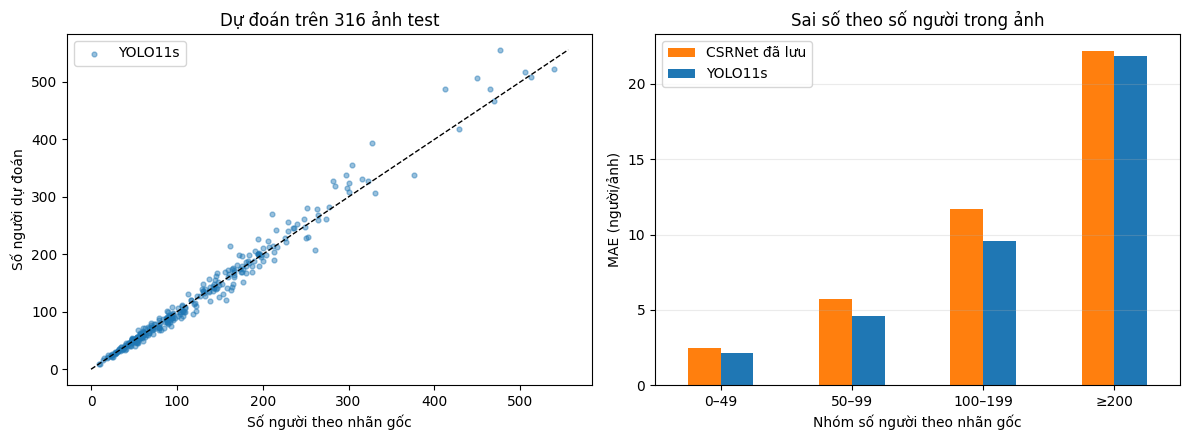

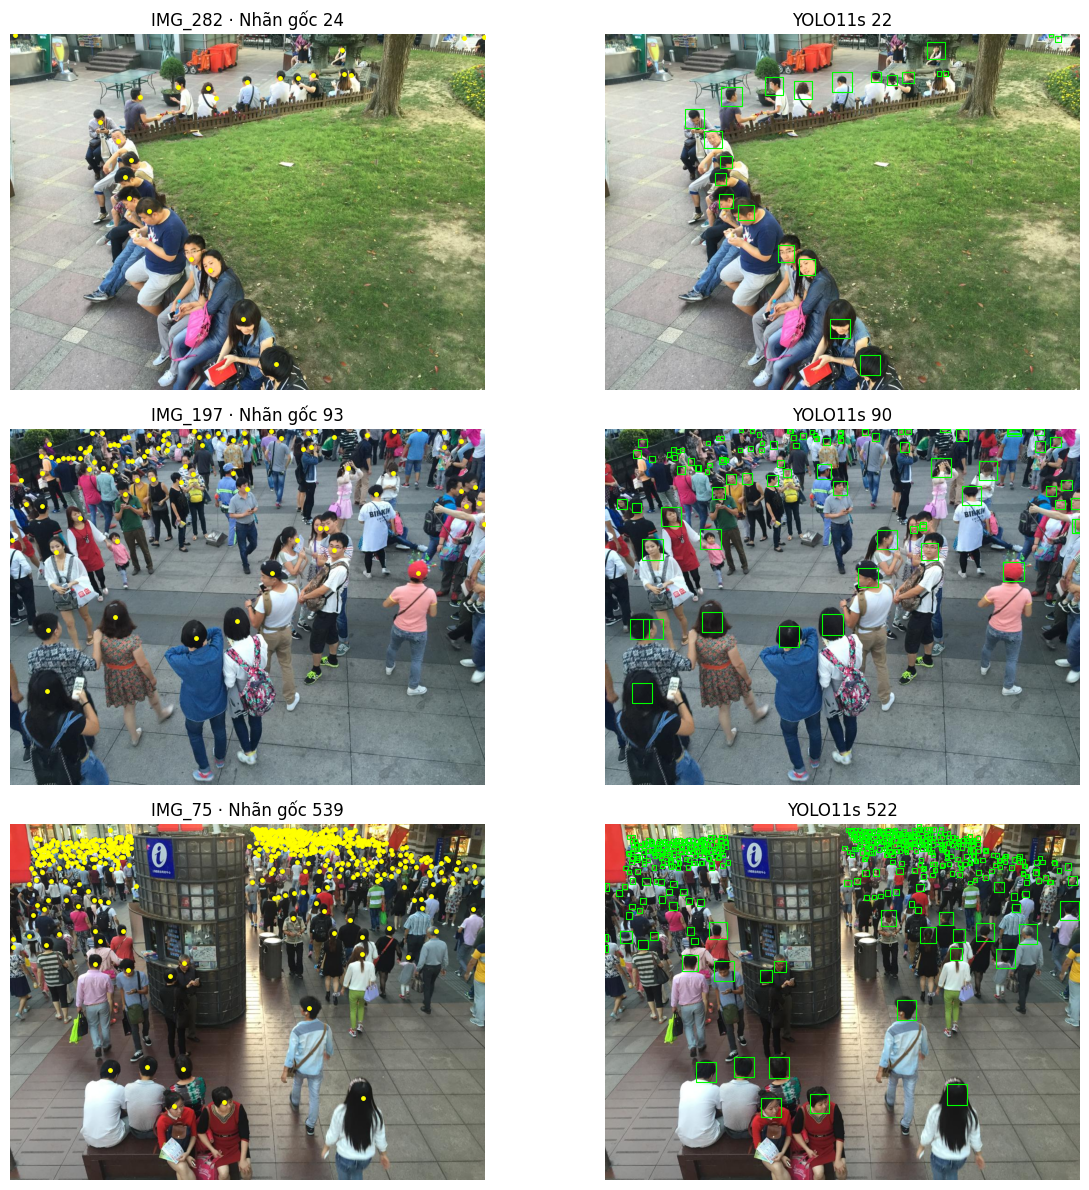

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(ground_truth, yolo_counts, s=12, alpha=0.45, label="YOLO11s")
upper = max(ground_truth.max(), yolo_counts.max())
if csr_recomputed is not None:
    axes[0].scatter(ground_truth, csr_counts, s=12, alpha=0.35, label="CSRNet chạy lại")
    upper = max(upper, csr_counts.max())
axes[0].plot([0, upper], [0, upper], "k--", linewidth=1)
axes[0].set(xlabel="Số người theo nhãn gốc", ylabel="Số người dự đoán", title="Dự đoán trên 316 ảnh test")
axes[0].legend()

density_plot = by_density.set_index("group_gt")[["csrnet_saved_mae", "yolo_mae"]].rename(columns={
    "csrnet_saved_mae": "CSRNet đã lưu",
    "yolo_mae": "YOLO11s",
})
density_plot.plot.bar(ax=axes[1], rot=0, color=["tab:orange", "tab:blue"])
axes[1].set(xlabel="Nhóm số người theo nhãn gốc", ylabel="MAE (người/ảnh)", title="Sai số theo số người trong ảnh")
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(OUT / "comparison_test.png", dpi=160)
plt.show()

ordered = np.argsort(ground_truth)
picks = [ordered[10], ordered[len(ordered) // 2], ordered[-1]]
fig, axes = plt.subplots(len(picks), 2, figsize=(13, 12))
for index, (ax_gt, ax_yolo) in zip(picks, axes):
    item, record = test_items[index], test_records[index]
    image = cv2.cvtColor(read_image(item["image"]), cv2.COLOR_BGR2RGB)
    for ax in (ax_gt, ax_yolo):
        ax.imshow(image)
        ax.axis("off")
    ax_gt.scatter(item["points"][:, 0], item["points"][:, 1], s=6, color="yellow")
    ax_gt.set_title(f"{item['name']} · Nhãn gốc {ground_truth[index]}")
    draw_boxes(ax_yolo, record["boxes"][record["scores"] > test_conf], "lime")
    title = f"YOLO11s {yolo_counts[index]}"
    if csr_recomputed is not None:
        title += f" · CSRNet {csr_counts[index]:.1f}"
    ax_yolo.set_title(title)
fig.tight_layout()
fig.savefig(OUT / "test_samples.png", dpi=140)
plt.show()

## 8. Xuất trọng số và kết quả

**yolo_partb_outputs.zip** chứa trọng số YOLO, cấu hình và ngưỡng suy luận, bảng so sánh, dự đoán từng ảnh, danh sách train/validation/test, log huấn luyện và các hình dùng cho báo cáo.

Theo mặc định ZIP nằm ở **/content/yolo_partb_outputs.zip**. Nếu bật lưu Drive, ZIP nằm trong **MyDrive/ShanghaiTech_YOLO**.

In [ ]:
speed_ms = float(np.mean([row["speed_ms"] for row in test_records]))
results = {
    "dataset": "ShanghaiTech Part B",
    "dataset_reference": "tthien/shanghaitech/versions/1",
    "splits": {"train": len(train_items), "val": len(val_items), "test": len(test_items)},
    "cfg": CFG,
    "ultralytics_version": ultralytics.__version__,
    "torch_version": str(torch.__version__),
    "gpu": GPU,
    "training_minutes": training_minutes,
    "selected_on_validation": best_count,
    "test_confidence": test_conf,
    "test_mae": yolo_test["mae"],
    "test_rmse": yolo_test["rmse"],
    "yolo_test": {
        **yolo_test,
        "images_reaching_max_det_at_score_floor": n_capped,
        "preprocess_inference_postprocess_ms_per_image_batch_1": speed_ms,
    },
    "csrnet_saved": CSR_SAVED,
    "csrnet_recomputed": csr_recomputed,
    "yolo_minus_csrnet_saved": {"mae": delta_mae, "rmse": delta_rmse},
    "paired_bootstrap_mae_yolo_minus_csrnet_recomputed_95pct": paired_mae_ci,
    "by_count": group_rows,
}
(OUT / "results.json").write_text(
    json.dumps(results, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
)
archive = shutil.make_archive(str(EXPORT / "yolo_partb_outputs"), "zip", root_dir=OUT)
print(f"Đã lưu {archive}")

Đã lưu /content/yolo_partb_outputs.zip


In [ ]:
if not SAVE_TO_DRIVE:
    from google.colab import files

    files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>